# Generating Peak Pair Hashes for query and reference files

## Constellations

Transform audio file into freq domain and select prominent peaks

In [20]:
import sys
sys.path.append('..')

from main import *

sample_rate = 44100
window_length = 2048
hop_length = 1024
n_fft = 2048

spectrogram = to_spectrogram('../audio_data/database/010672.mp3', sample_rate, window_length, hop_length, n_fft)


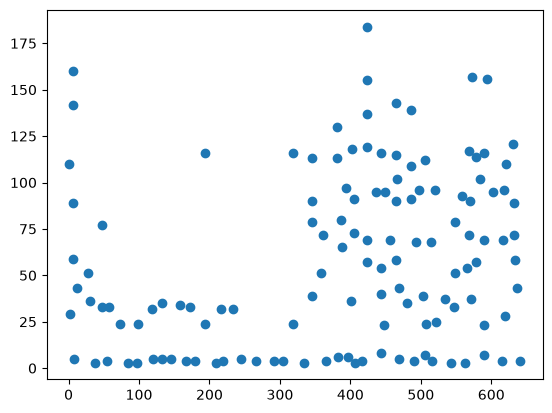

In [47]:
import matplotlib.pyplot as plt

peak_level_threshold_db = 20

peaks = constellation(spectrogram, peak_level_threshold_db)
plt.scatter(peaks[:,1], peaks[:,0])


## Peak pairing hashes

6, 80, 4


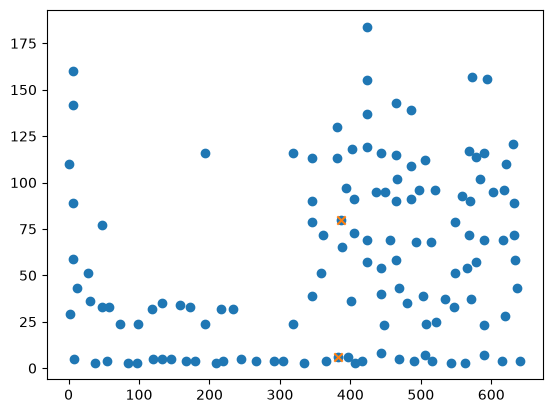

In [65]:
hashes = generate_hashes(peaks)

# hash: [hash_val, t_anchor]
# hash_val = (int(f_anchor & 0x3FFF) << 18) | (int(f_target & 0x3FF) << 8) | int(delta_t & 0xFF)

hash_index = 500

hash = hashes[hash_index]
t_anchor = hash[1]

# decode information stored in hash
f_anchor = hash[0] >> 18
f_target = hash[0] >> 8 & 0x3FF
delta_t = hash[0] & 0xFF
t_target = t_anchor + delta_t


plt.scatter(peaks[:,1], peaks[:,0])
plt.scatter([t_anchor, t_target], [f_anchor, f_target], marker='x')


# Match query Files